# 🐍 Python Foundations for AI
## Class 5 — Comprehensions & Functional Thinking

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos** · AI Engineer

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
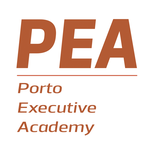
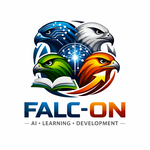
</div>

---

### 📋 What we'll cover today

| # | Topic |
|---|-------|
| 1 | Why comprehensions? |
| 2 | List comprehensions |
| 3 | Dict and set comprehensions |
| 4 | Sorting by a field — `sorted()` with a key, and `lambda` |
| 5 | `map`, `filter`, `zip`, `any`, `all` |
| 6 | 🔗 Capstone — preparing a batch of questions for FALC-ON AI |

### 🎯 Learning outcomes

By the end of this class you will be able to:

- Replace a build-a-list loop with one readable line
- Build dictionaries and sets the same way
- Sort a list of dictionaries by any field
- Use Python's built-in helpers to pair, check and transform data

### 🤖 Why this matters for AI

AI work is about **batches**: hundreds of questions, messages or tickets at a time. You constantly need to

- **transform** each item — every question into a message
- **select** some of them — only the unhappy customers
- **check** the batch — is anything empty before we call the model?
- **pair** things up — each question with its answer

Nothing today lets you do something you could not already do with a loop. Everything today lets you say it in **one line instead of four**.

---
## 1. Why Comprehensions?

In Class 4, `build_history()` used a pattern you have written many times: an empty list, a loop, `.append()`.

In [ ]:
questions = ["What is AI?", "How do I learn Python?", "Is there homework?"]

In [ ]:
# The way you know: empty list, loop, append
messages = []
for question in questions:
    messages.append({"role": "user", "content": question})

print(messages)

In [ ]:
# The same list, as a comprehension
messages = [{"role": "user", "content": question} for question in questions]

print(messages)

Four lines became one, and it reads as a sentence: *"a user message for every question in questions"*.

A comprehension is the right tool when you **build a new list from an old one**. It is the wrong tool when the loop prints, or updates a running total, or does several things. If the comprehension is harder to read than the loop, keep the loop.

---
## 2. List Comprehensions

Every comprehension has the same three parts, in the same order:

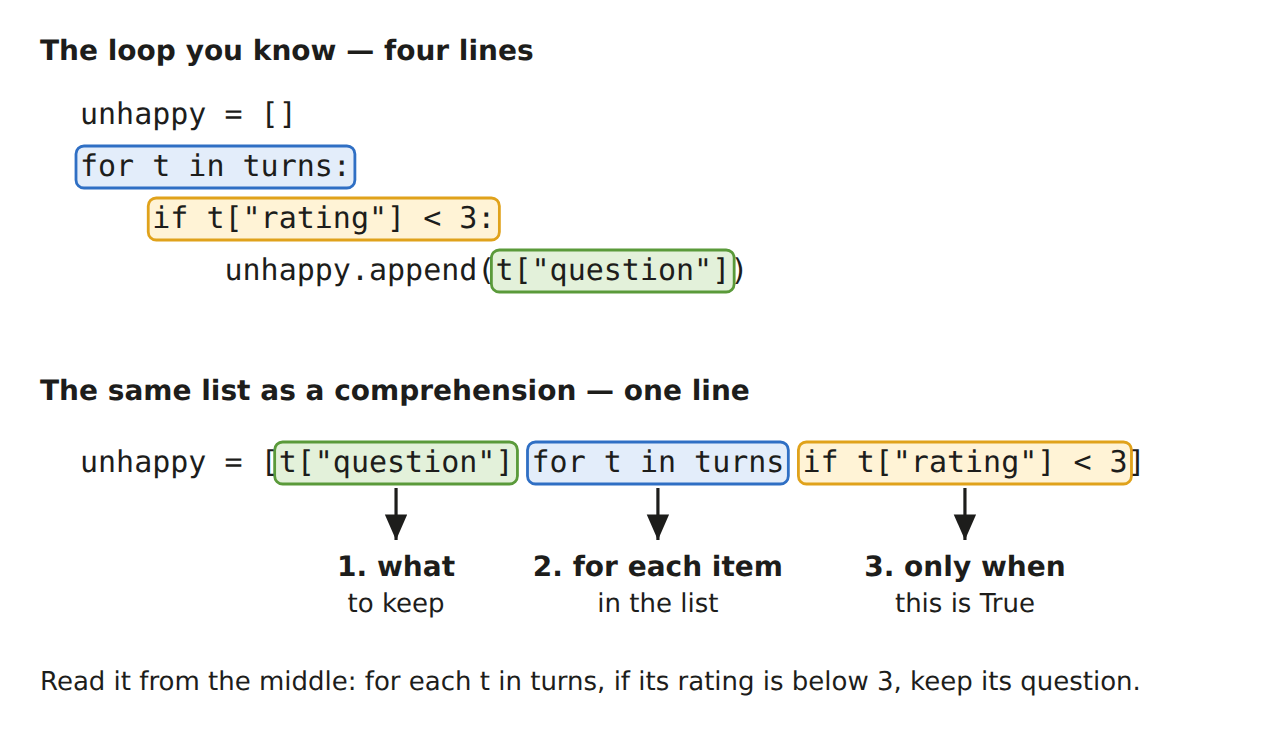

| You want | Write |
|----------|-------|
| One field of each item | `[t["question"] for t in turns]` |
| A calculation on each | `[r * 20 for r in ratings]` |
| Only some of them | `[r for r in ratings if r < 3]` |
| Both at once | `[r * 20 for r in ratings if r < 3]` |

Today's data: one day of FALC-ON AI conversations. Each turn is a dictionary with the question, its topic, the answer given, and the user's rating from 1 to 5.

In [ ]:
UNKNOWN = "Sorry, I don't know that yet."

turns = [
    {"question": "how many classes?",         "topic": "classes",  "answer": "The course has 10 classes.",              "rating": 5},
    {"question": "is there homework?",        "topic": "homework", "answer": UNKNOWN,                                   "rating": 2},
    {"question": "who teaches?",              "topic": "teachers", "answer": "Alexandra Oliveira and Catarina Santos.", "rating": 4},
    {"question": "when is the exam?",         "topic": "exam",     "answer": UNKNOWN,                                   "rating": 1},
    {"question": "what is colab?",            "topic": "colab",    "answer": "We write our code in Google Colab.",      "rating": 5},
    {"question": "how many hours per class?", "topic": "hours",    "answer": "The course has 10 classes.",              "rating": 3},
]
print(len(turns), "turns")

In [ ]:
# One field of each item
ratings = [t["rating"] for t in turns]
print(ratings)

In [ ]:
# A calculation on each item: the rating as a percentage
percentages = [r * 20 for r in ratings]
print(percentages)

In [ ]:
# Only some items: the low ratings
low = [r for r in ratings if r < 3]
print(low)

In [ ]:
# Both: the questions of the unhappy users
unhappy = [t["question"] for t in turns if t["rating"] < 3]
print(unhappy)

---
## 3. Dict and Set Comprehensions

The same idea, with different brackets:

| Brackets | You get | Shape |
|----------|---------|-------|
| `[ ... ]` | a **list** | `[value for item in things]` |
| `{ ... : ... }` | a **dictionary** | `{key: value for item in things}` |
| `{ ... }` | a **set** | `{value for item in things}` |

### A dictionary comprehension

Two expressions with a colon between them: the **key** and the **value**. It turns a list of records into a **lookup table**.

In [ ]:
rating_of = {t["question"]: t["rating"] for t in turns}
print(rating_of)

In [ ]:
print(rating_of["who teaches?"])             # 4 - looked up by question

### A set comprehension

Curly brackets without a colon give a **set**: each value once. As in Class 2, print a set with `list()` — the order can vary.

In [ ]:
topics = {t["topic"] for t in turns}
print(len(topics), "different topics")
print(list(topics))                          # in any order

---
## 4. Sorting by a Field — `sorted()` with a `key`, and `lambda`

You know `sorted()` from Class 2. `reverse=True` puts the biggest first:

In [ ]:
print(sorted(ratings, reverse=True))         # biggest first

### The problem: what should Python sort on?

`turns` is a list of **dictionaries**. Should a turn come first because of its question? Its topic? Its rating? Python cannot guess — `sorted(turns)` alone stops with an error.

You tell it with the parameter `key=`. Let's build it in three steps.

### Step 1 — a function that gives the value to sort on

First, an ordinary function: it takes **one** turn and returns its rating. Call it yourself on the first turn, as usual — with `()`:

In [ ]:
def get_rating(turn):
    """Return what we sort on: the turn's rating."""
    return turn["rating"]

print(get_rating(turns[0]))                  # 5 - the rating of the first turn

### Step 2 — hand the function to `sorted()`, and let it do the calling

`key=get_rating` tells `sorted()`: *"to put the turns in order, don't look at the whole dictionaries — call `get_rating()` on each turn, and compare the results."*

Behind the scenes, `sorted()` first does this for you — one call per turn:

In [ ]:
print([get_rating(turn) for turn in turns])  # [5, 2, 4, 1, 5, 3] - the values sorted() compares

Then it puts the **turns** in the order of those values — 1, 2, 3, 4, 5, 5 — and gives you back the whole turns, not just the numbers.

### Step 3 — why `get_rating` has no `()` after `key=`

| You write | What it means |
|-----------|---------------|
| `get_rating(turns[0])` | **you** call the function **now**, on one turn — and get a value: `5` |
| `get_rating` | the function **itself**, not called yet — you hand it over, and `sorted()` calls it **later**, once for every turn |

Think of a recipe: `get_rating(turns[0])` is cooking one dish yourself; `key=get_rating` is handing the recipe to `sorted()`, which cooks it for every turn.

> ⚠️ `key=get_rating()` — with `()` — would call the function right away, with no turn to give it, and Python stops with an error: `missing 1 required positional argument: 'turn'`.

In [ ]:
by_rating = sorted(turns, key=get_rating)    # the function itself - sorted() calls it on every turn

for t in by_rating:
    print(t["rating"], t["question"])

### `lambda` — the same function, written on the spot

`get_rating()` is a whole `def`, with a name, for a one-line job that `sorted()` needs just once. A **lambda** writes that small function **right where it is used**, with no name.

The syntax:

```
lambda parameter: value_to_return
```

| Piece | Means |
|-------|-------|
| `lambda` | *"here is a small function"* |
| `parameter` | the input — like the parameter of a `def`; several are separated by commas |
| `:` | separates the input from the result |
| `value_to_return` | **one expression**: what the function gives back — no `return` needed |

| With `def` | As a lambda |
|------------|-------------|
| `def get_rating(turn):`<br>`    return turn["rating"]` | `lambda turn: turn["rating"]` |

Read `key=lambda turn: turn["rating"]` as *"sort the turns by their rating"*. Like `get_rating`, the lambda is handed over **without being called**: `sorted()` calls it on every turn.

In [ ]:
by_rating = sorted(turns, key=lambda turn: turn["rating"])

print([t["rating"] for t in by_rating])      # [1, 2, 3, 4, 5, 5] - the same order as with get_rating

> ⚠️ A lambda holds **one expression** only — no `if` blocks, no loops. As soon as you need more, write a `def`.

> 💡 **When to use which:** a lambda is for a tiny function you **hand to another function** — `sorted()` here, `map()` and `filter()` in the next section. If you would give it a name and use it again, write a `def`.

In [ ]:
# The two best-rated turns: sort biggest first, then slice
best = sorted(turns, key=lambda turn: turn["rating"], reverse=True)[:2]
print([t["question"] for t in best])

---
## 5. `map`, `filter`, `zip`, `any`, `all`

### `map` and `filter` — so you recognise them

`map(function, things)` runs the function on **every** item. `filter(function, things)` keeps the items where the function says `True`. Wrap them in `list()` to see the result. Both take a function as their first input — the place for a lambda.

> 💡 A list comprehension does both jobs and is usually easier to read. Learn `map` and `filter` because you will meet them in other people's code.

In [ ]:
print(list(map(lambda r: r * 20, ratings)))              # like [r * 20 for r in ratings]
print(list(filter(lambda r: r < 3, ratings)))            # like [r for r in ratings if r < 3]

### `zip` — walk two lists together

`zip(a, b)` pairs the first item of `a` with the first of `b`, the second with the second, and so on.

In [ ]:
new_topics = ["homework", "exam"]
new_answers = ["There is no homework.", "There is no exam - only a final project."]

for topic, answer in zip(new_topics, new_answers):
    print(f"{topic}: {answer}")

### `any` and `all` — check a whole batch

| Built-in | Answers |
|----------|---------|
| `any(checks)` | is **at least one** of them `True`? |
| `all(checks)` | are **all** of them `True`? |

They take a list of `True` / `False` values — exactly what a comprehension with a comparison produces.

In [ ]:
checks = [r == 1 for r in ratings]
print(checks)

In [ ]:
print("Anyone very unhappy?", any(checks))                                # True
print("Every question answered?", all([t["answer"] != UNKNOWN for t in turns]))   # False

> 🤖 **AI Connection**
>
> This is how you check a batch **before** calling a model: `all([q != "" for q in questions])` makes sure no empty question wastes a call — and money.

---
## 6. 🔗 Capstone — Preparing a Batch of Questions for FALC-ON AI

### From Class 4 to today

In Class 4, a `while` loop kept FALC-ON AI running: each time round, the user typed a question, and `chat_turn()` cleaned it with `clean_text()`, answered it, and stored the messages built by `make_message()`. The questions arrived **one after another**, and each was answered **as soon as it was typed** — the loop never sees the next question in advance. That is right for a chat.

But a real app often receives **many questions at once**, already in a list — and every question sent to an AI model costs time and money. With the whole batch in front of us, we can do something a chat loop cannot: look at **all** the questions **before** answering any — drop the empty ones, keep each repeated question once, and check the batch.

Two jobs are **the same** in both examples, and today we **reuse the Class 4 functions** for them — a comprehension simply calls them on every question of the list:

| Same job | Class 4 — one question per turn of the loop | Today — the whole list at once |
|----------|----------------------------------------------|--------------------------------|
| Tidy the question | `clean_text(question)` | `[clean_text(q) for q in incoming]` |
| Make a message for the model | `make_message("user", question)` | `[make_message("user", q) for q in unique]` |

The other steps are **new**, because they only make sense when the whole batch is in front of you: dropping empty and repeated questions, checking the batch, and reusing answers.

### The situation

Six questions have just arrived for FALC-ON AI. Sending a question to an AI model costs **time and money**, so before we send anything, we prepare the batch: tidy it, throw away what is useless, and check it. Then we put the model's answers to good use.

Each step is **one line** — that is what today's tools are for:

| Step | Job | Tool |
|------|-----|------|
| 1 | Tidy every question | list comprehension + `clean_text()` from Class 4 |
| 2 | Drop the empty ones | list comprehension with `if` |
| 3 | Keep each question once | set comprehension |
| 4 | Check the batch before sending | `all()`, `any()` |
| 5 | Turn each question into a message for the model | list comprehension + `make_message()` from Class 4 |
| 6 | Remember each answer, to reuse it | `zip()` and a dictionary comprehension |
| 7 | Find the answer users liked least | `sorted()` with a `lambda` |

The two functions from Class 4 that we reuse — copied here, so this notebook runs on its own:

In [ ]:
def clean_text(text):
    """Return the text in lower case, without spaces at the ends."""
    return text.lower().strip()

def make_message(role, content):
    """Build one chat message."""
    return {"role": role, "content": content}

In [ ]:
incoming = ["  What is Python? ", "", "HOW do I start?", "what is python?", "   ", "Is Colab free?"]
print(len(incoming), "questions arrived")

### Step 1 — Tidy every question

In Class 4, `clean_text()` tidied **one** question. A comprehension calls it on **every** question, in one line — so `"  What is Python? "` and `"what is python?"` become the same question.

In [ ]:
cleaned = [clean_text(q) for q in incoming]
print(cleaned)

### Step 2 — Drop the empty ones

Two questions were only spaces: after tidying they are empty, `""`. Sending them would cost money for nothing.

In [ ]:
batch = [q for q in cleaned if q != ""]
print(batch)

### Step 3 — Keep each question once

`"what is python?"` arrived twice. A set comprehension keeps each value once, and `sorted()` puts the set back in a fixed order.

In [ ]:
unique = sorted({q for q in batch})
print(unique)                                # 3 questions instead of 6

### Step 4 — Check the batch before sending

Is every item really a question? Is any question too long for the model? Each check is one line.

In [ ]:
print("Does every one contain a question mark?", all(["?" in q for q in unique]))
print("Any longer than 100 characters?", any([len(q) > 100 for q in unique]))

### Step 5 — Turn each question into a message for the model

A model receives messages in the Class 2 shape: a dictionary with a `role` and a `content`. In Class 4, `make_message()` built one inside every `chat_turn()`; here, one comprehension builds them all:

In [ ]:
messages = [make_message("user", q) for q in unique]

for message in messages:
    print(message)

### Step 6 — Remember each answer, to reuse it

The model answered the three questions, in the same order. With `zip()` and a dictionary comprehension, each question is paired with its answer. Next time someone asks the same question, FALC-ON AI answers from the dictionary — **without calling the model again**.

In [ ]:
answers = ["Start with Class 1: variables and print().", "Yes, Colab is free.", "Python is a programming language."]

answer_for = {q: a for q, a in zip(unique, answers)}
print(answer_for["is colab free?"])          # answered without asking the model

### Step 7 — Find the answer users liked least

Users rated each answer from 1 to 5. We pair everything into one list of dictionaries, then sort by rating with a `lambda`: the first one is the answer to improve.

In [ ]:
ratings = [2, 5, 4]

reviews = [{"question": q, "answer": a, "rating": r} for q, a, r in zip(unique, answers, ratings)]
worst = sorted(reviews, key=lambda review: review["rating"])[0]

print(f"Lowest rating ({worst['rating']}): {worst['question']} -> {worst['answer']}")

> 🤖 Seven steps, seven lines. Real AI applications do exactly this before and after every call to a model: clean the input, skip what is useless, check it, send it — then store and review what comes back.

> 🔁 **Compare with Class 4:** `clean_text()` and `make_message()` are the same functions — Class 4 called them on one question per turn of the loop; today a comprehension calls them on every question of the list. Functions say **what** to do with one item; comprehensions do it for **every** item.

---

### 🎉 That's Class 5!

| Concept | Key syntax |
|---------|------------|
| List comprehension | `[value for item in things]` |
| …with a condition | `[value for item in things if test]` |
| Dict comprehension | `{key: value for item in things}` |
| Set comprehension | `{value for item in things}` |
| Sort biggest first | `sorted(things, reverse=True)` |
| Sort by a field | `sorted(things, key=get_rating)` |
| Lambda — a small function, written where it is used | `sorted(things, key=lambda t: t["rating"])` |
| Run on every item | `list(map(function, things))` |
| Keep some items | `list(filter(function, things))` |
| Walk two lists together | `zip(a, b)` |
| At least one `True`? | `any(checks)` |
| All `True`? | `all(checks)` |

> 💡 **The rule for using them:** a comprehension should be *easier* to read than the loop it replaces. One `for` and at most one `if` is comfortable. Anything more — write the loop.

> 🤖 **The big picture:** Reviewing what an AI assistant got wrong, and feeding it back into its knowledge, is how real AI products improve. With comprehensions, each question about the batch is one line.

➡️ Now open the **exercises notebook**.